# 01 Eksplorasi Data Awal (Data Exploration)

---
### 1. Setup Environment


In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path(r"c:\Project\napasloka\napasloka")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


---
### 2. Pemuatan Modul & Pembacaan Dataset


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.config import load_yaml_config

# Memuat konfigurasi stasiun
locations_cfg = load_yaml_config("locations.yaml").get("locations", [])
print(f"Total stasiun terkonfigurasi: {len(locations_cfg)} stasiun")

# Membaca dataset terproses
df_co = pd.read_csv(ROOT_DIR / "data" / "processed" / "jabodetabek_co_dataset.csv")
df_co2 = pd.read_csv(ROOT_DIR / "data" / "processed" / "jabodetabek_co2_dataset.csv")

# Standardisasi waktu
df_co["datetime"] = pd.to_datetime(df_co["datetime"], utc=True).dt.tz_convert("Asia/Jakarta")
df_co2["datetime"] = pd.to_datetime(df_co2["datetime"], utc=True).dt.tz_convert("Asia/Jakarta")

print(f"Dataset CO  : {len(df_co):,} baris | Rentang: {df_co['datetime'].min()} s.d. {df_co['datetime'].max()}")
print(f"Dataset CO₂ : {len(df_co2):,} baris | Rentang: {df_co2['datetime'].min()} s.d. {df_co2['datetime'].max()}")


Total stasiun terkonfigurasi: 15 stasiun
Dataset CO  : 262,980 baris | Rentang: 2024-10-26 07:00:00+07:00 s.d. 2026-10-26 18:00:00+07:00
Dataset CO₂ : 262,980 baris | Rentang: 2024-10-26 07:00:00+07:00 s.d. 2026-10-26 18:00:00+07:00


---
### 3. Pemeriksaan Missing Values & Kelengkapan Data


In [6]:
print("Missing Values Dataset CO")
print(df_co.isnull().sum())

print("Missing Values Dataset CO2")
print(df_co2.isnull().sum())

# Pemeriksaan jumlah baris per lokasi pengamatan
stasiun_counts = df_co.groupby("location").size()
print(f"Jumlah observasi per lokasi pengamatan (CO): {stasiun_counts.unique().tolist()} baris per lokasi")

Missing Values Dataset CO
location                0
latitude                0
longitude               0
datetime                0
temperature_2m          0
relative_humidity_2m    0
rain                    0
wind_speed_100m         0
carbon_monoxide         0
dtype: int64
Missing Values Dataset CO2
location                0
latitude                0
longitude               0
datetime                0
temperature_2m          0
relative_humidity_2m    0
rain                    0
wind_speed_100m         0
carbon_dioxide          0
dtype: int64
Jumlah observasi per lokasi pengamatan (CO): [17532] baris per lokasi


---
### 4. Statistik Deskriptif Konsentrasi Polutan & Cuaca


In [13]:
df_desk = df_co.copy()
df_desk["carbon_dioxide"] = df_co2["carbon_dioxide"]
cols = ["carbon_monoxide", "carbon_dioxide", "temperature_2m", "relative_humidity_2m", "rain", "wind_speed_100m"]
display(df_desk[cols].describe().round(2))

,carbon_monoxide,carbon_dioxide,temperature_2m,relative_humidity_2m,rain,wind_speed_100m
count,262980.00,262980.00,262980.00,262980.00,262980.00,262980.00
mean,1642.33,463.28,27.27,78.74,0.31,11.42
std,1425.54,20.07,2.81,14.46,1.09,6.30
min,0.00,422.00,18.90,19.14,0.00,0.00
25%,689.00,449.00,25.10,69.77,0.00,6.68
50%,1206.00,457.00,26.70,82.29,0.00,10.42
75%,2107.00,472.00,29.20,90.29,0.10,15.16
max,19559.00,631.00,38.35,100.00,27.60,45.28


---
### 5. Visualisasi Distribusi & Korelasi Polutan


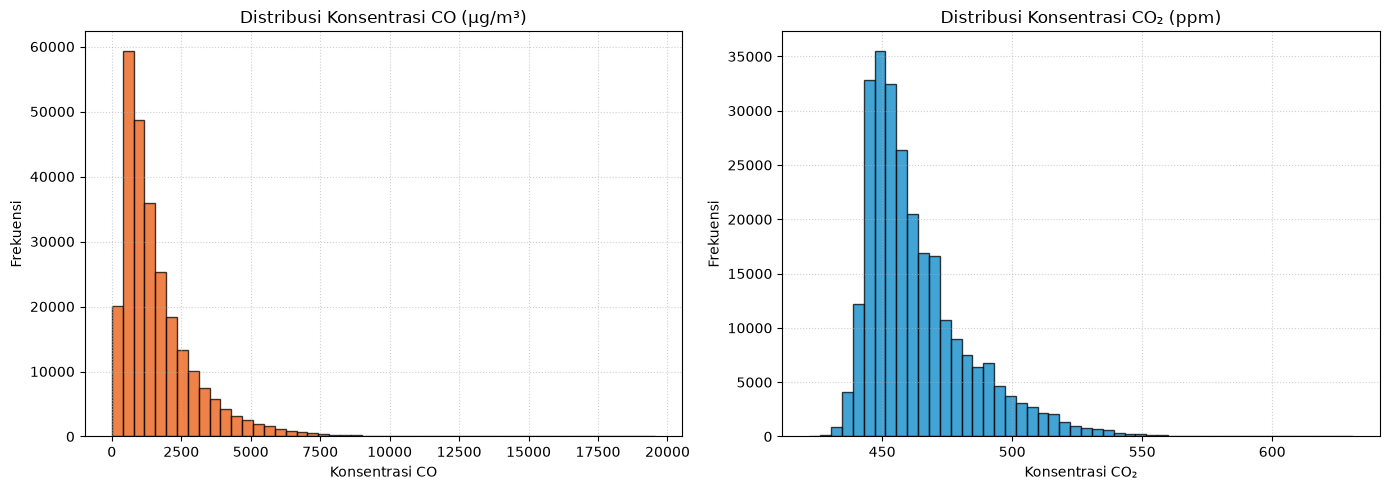

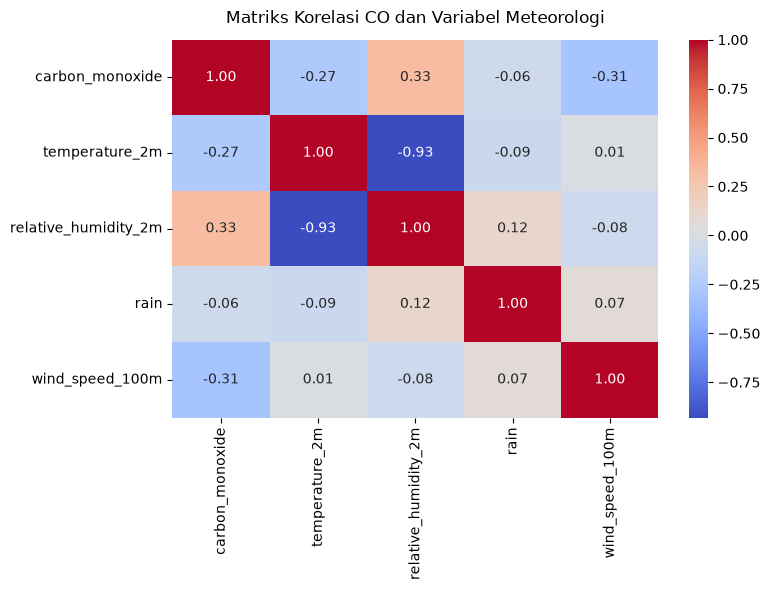

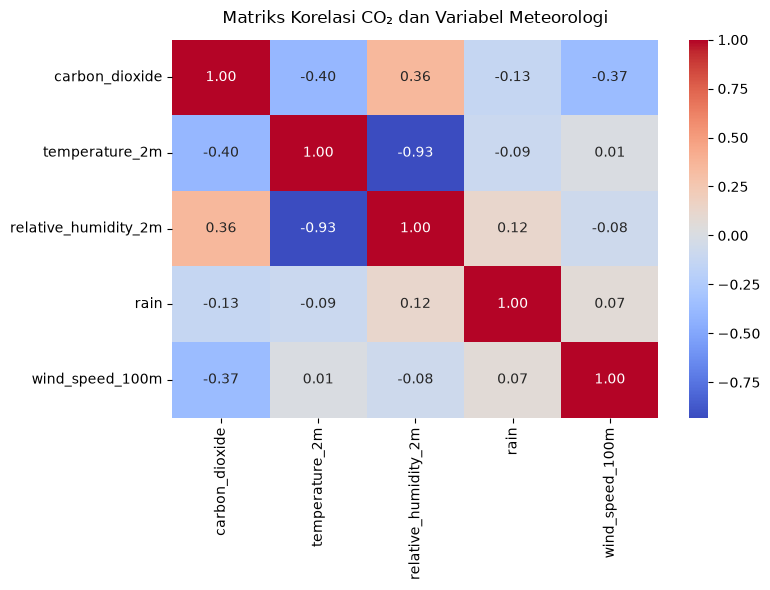

In [14]:
cols_co = ["carbon_monoxide", "temperature_2m", "relative_humidity_2m", "rain", "wind_speed_100m"]
cols_co2 = ["carbon_dioxide", "temperature_2m", "relative_humidity_2m", "rain", "wind_speed_100m"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi CO
axes[0].hist(df_co["carbon_monoxide"].dropna(), bins=50, color="#ea580c", alpha=0.75, edgecolor="black")
axes[0].set_title("Distribusi Konsentrasi CO (µg/m³)", fontsize=12)
axes[0].set_xlabel("Konsentrasi CO")
axes[0].set_ylabel("Frekuensi")
axes[0].grid(True, linestyle=":", alpha=0.6)

# Distribusi CO2
axes[1].hist(df_co2["carbon_dioxide"].dropna(), bins=50, color="#0284c7", alpha=0.75, edgecolor="black")
axes[1].set_title("Distribusi Konsentrasi CO₂ (ppm)", fontsize=12)
axes[1].set_xlabel("Konsentrasi CO₂")
axes[1].set_ylabel("Frekuensi")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# Heatmap Korelasi Meteorologi terhadap CO
plt.figure(figsize=(8, 6))
corr = df_co[cols_co].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Matriks Korelasi CO dan Variabel Meteorologi", fontsize=12, pad=12)
plt.tight_layout()
plt.show()


# Heatmap Korelasi Meteorologi terhadap CO2
plt.figure(figsize=(8, 6))
corr = df_co2[cols_co2].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Matriks Korelasi CO₂ dan Variabel Meteorologi", fontsize=12, pad=12)
plt.tight_layout()
plt.show()


### 6. Pola Temporal

In [26]:
df_co["hour"] = df_co["datetime"].dt.hour
diurnal_co = df_co.groupby("hour")["carbon_monoxide"].mean()

df_co2["hour"] = df_co2["datetime"].dt.hour
diurnal_co2 = df_co2.groupby("hour")["carbon_dioxide"].mean()

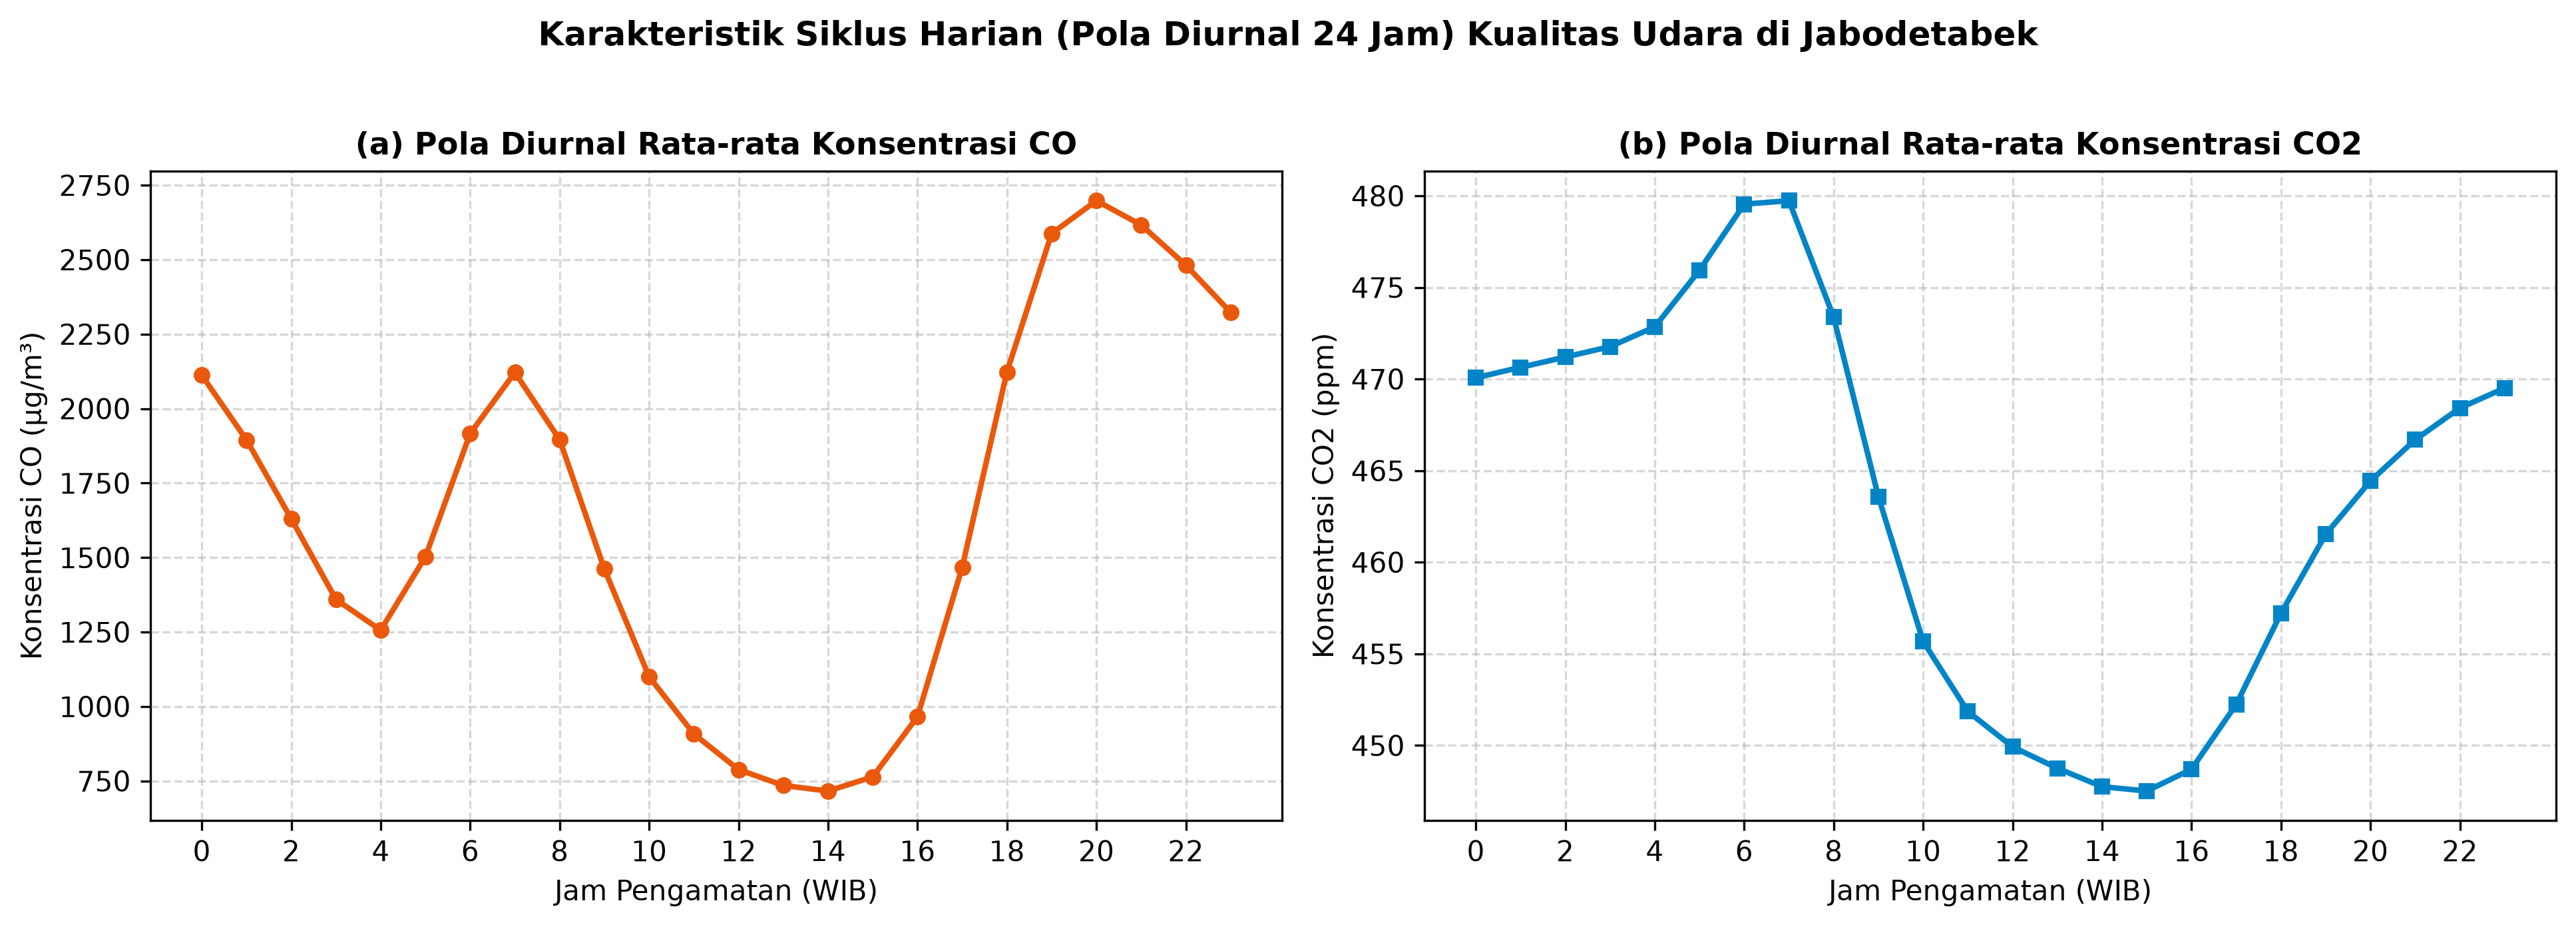

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), dpi=300)

# Panel CO
ax1.plot(diurnal_co.index, diurnal_co.values, color="#ea580c", marker="o", linewidth=2, markersize=5)
ax1.set_title("(a) Pola Diurnal Rata-rata Konsentrasi CO", fontsize=11, fontweight="bold")
ax1.set_xlabel("Jam Pengamatan (WIB)", fontsize=10)
ax1.set_ylabel("Konsentrasi CO (µg/m³)", fontsize=10)
ax1.set_xticks(range(0, 24, 2))
ax1.grid(True, linestyle="--", alpha=0.5)

# Panel CO2
ax2.plot(diurnal_co2.index, diurnal_co2.values, color="#0284c7", marker="s", linewidth=2, markersize=5)
ax2.set_title("(b) Pola Diurnal Rata-rata Konsentrasi CO2", fontsize=11, fontweight="bold")
ax2.set_xlabel("Jam Pengamatan (WIB)", fontsize=10)
ax2.set_ylabel("Konsentrasi CO2 (ppm)", fontsize=10)
ax2.set_xticks(range(0, 24, 2))
ax2.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Karakteristik Siklus Harian (Pola Diurnal 24 Jam) Kualitas Udara di Jabodetabek", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
out_diurnal = ROOT_DIR / "artifacts" / "gambar_eda_diurnal_cycle.png"

plt.show()